# Chapitre 9 - Cours 3 : validation atomique et transactions distribuées (2PC)

Ce notebook couvre la partie *Atomic Commit and Two-Phase Commit (2PC)* de la section
*Distributed Transactions and Consensus* (*From single-node to distributed atomic
commit*, *Introduction to two-phase commit*, *A system of promises*, *Coordinator
failure*, *Three-phase commit*) et la partie *Distributed Transactions in Practice*
(*Exactly-once message processing*, *XA transactions*, *Holding locks while in doubt*,
*Recovering from coordinator failure*, *Limitations of distributed transactions*). Les
transactions sur un seul nœud (ACID, isolation) ont été étudiées au chapitre
7 ; le consensus tolérant aux pannes, qui permet de dépasser les limites
de 2PC, est l'objet du cours suivant.

**Plan.**

1. De la validation locale à la validation distribuée.
2. Le protocole de validation à deux phases.
3. Un système de promesses : 2PC face aux pannes.
4. La panne du coordinateur : participants en doute.
5. Pourquoi ne pas décider seul ? (validation à trois phases).
6. Transactions distribuées hétérogènes et XA.
7. Verrous tenus en doute et reprise après panne.
8. Les limites des transactions XA.

Le protocole est simulé sur le simulateur à événements discrets `ddia.sim` (réseau
asynchrone, pannes de nœuds), avec les classes `Coordinator2PC` et `Participant2PC` de
[`ddia/transactions.py`](../../ddia/transactions.py) ; la fonction `run_2pc` lance une
transaction et renvoie la trace des messages et une synthèse par participant.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import run_2pc, Participant2PC
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)

COULEUR_MSG = {"begin": SLATE, "prepare": INDIGO, "vote": VIOLET, "commit": GREEN, "abort": ROSE,
               "ack": GRAY, "status?": AMBER, "status": AMBER, "commit1": GREEN}


def frise(run, title, subtitle=None, t_max=None, width=11, labels=True):
    """Diagramme espace-temps d'une exécution de run_2pc : messages, verrous (bande
    sarcelle), période en doute (bande ambre), pannes et décisions."""
    noms = ["coord"] + [p.name for p in run.parts]
    t_max = t_max or run.t_max
    st = SpaceTime(noms, t_max=t_max, title=None, subtitle=subtitle, width=width,
                   time_label="temps (unités arbitraires)")
    st.ax.set_title(title, pad=18 if subtitle else 6)
    for p in run.parts:
        if p.lock_from is not None:
            fin = p.lock_until if p.lock_until is not None else t_max
            st.span(p.name, p.lock_from, fin, "", color=TEAL, alpha=0.15)
        if p.prepared_at is not None:
            fin = p.decided_at if p.decided_at is not None else t_max
            st.span(p.name, p.prepared_at, fin, "en doute", color=AMBER, alpha=0.3)
        if p.outcome:
            st.event(p.name, p.decided_at, p.outcome, kind="star",
                     color=GREEN if p.outcome == "commit" else ROSE)
    for d in run.net.trace:
        if d.t_send > t_max:
            continue
        kind = d.msg[0]
        lab = "/".join(str(x) for x in d.msg) if labels else ""
        lab = {"vote/yes": "oui", "vote/no": "non", "ack/commit": "ack", "ack/abort": "ack",
               "commit1": "commit"}.get(lab, lab)
        st.msg(d.src, d.t_send, d.dst, min(d.t_recv, t_max), lab, color=COULEUR_MSG.get(kind, SLATE),
               lost=d.lost, fontsize=7.5)
    for node in [run.coord] + run.parts:
        for t, what in node.log:
            if what == "panne":
                st.event(node.name, t, "panne", kind="crash")
            elif what == "redémarrage":
                st.event(node.name, t, "redémarrage", kind="tick")
            elif what.startswith("décision"):
                st.event(node.name, t, "", kind="point", color=INDIGO)
                st.note(t, node.name, what.replace(" journalisée", ""), dy=0.28, color=INDIGO, fontsize=8)
    return st

## 1. De la validation locale à la validation distribuée (section *From single-node to distributed atomic commit*)

Sur un seul nœud, l'atomicité tient à l'ordre des écritures sur disque : d'abord les
données, puis le **record de validation** (cours 1 du chapitre 7). Le moment où
le contrôleur d'**un** disque finit d'écrire ce record décide de tout : avant, la
transaction peut encore disparaître ; après, elle est validée.

Une transaction **distribuée** touche plusieurs nœuds : plusieurs partitions d'une base,
ou un index secondaire global stocké ailleurs que la donnée. Envoyer simplement « valide »
à chaque nœud ne suffit pas : un nœud peut détecter une violation de contrainte et
refuser, une requête peut se perdre, un nœud peut tomber avant d'écrire son record. Et
une fois validée sur un nœud, une transaction ne peut plus être retirée : d'autres
transactions ont pu lire ses données (*read committed*). Simulons cette **validation
naïve en une phase**, où le second participant viole une contrainte.

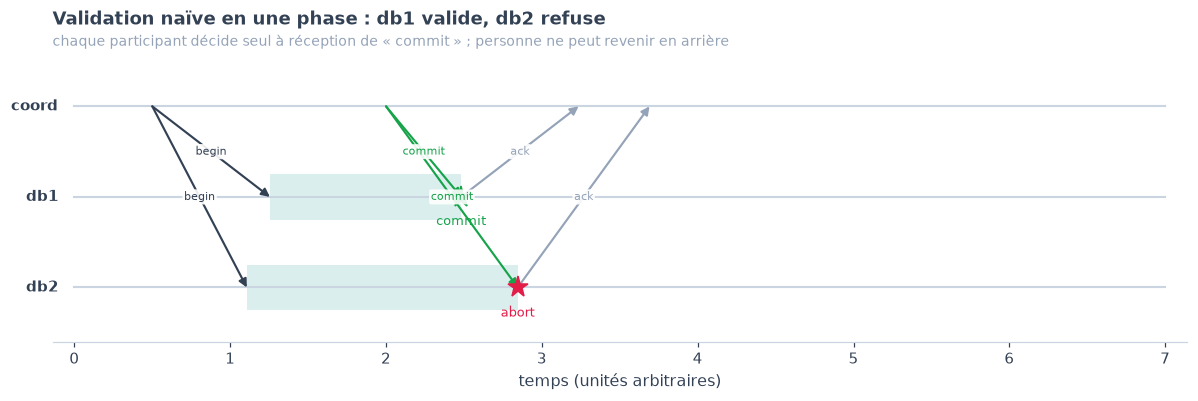

,participant,vote,issue
0,db1,yes,commit
1,db2,no,abort


In [2]:
naif = run_2pc(protocol="1pc", votes=["yes", "no"], t_max=7)
frise(naif, "Validation naïve en une phase : db1 valide, db2 refuse",
      "chaque participant décide seul à réception de « commit » ; personne ne peut revenir en arrière").show()
naif.summary[["participant", "vote", "issue"]]

db1 a validé, db2 a annulé : la transaction est **à moitié faite**, et l'atomicité est
perdue. Il faut que tous les participants valident, ou que tous annulent : c'est le
problème de la **validation atomique** (*atomic commitment*).

> **À retenir.** Sur un nœud, un seul disque prend la décision. Sur plusieurs nœuds,
> chacun peut échouer indépendamment : il faut un protocole pour que tous décident la
> même chose.

## 2. Le protocole de validation à deux phases (section *Introduction to two-phase commit*)

La **validation à deux phases** (2PC) est l'algorithme classique de validation atomique
entre plusieurs nœuds. Elle introduit un nouveau rôle, le **coordinateur** (ou
gestionnaire de transactions), souvent une bibliothèque dans le processus de
l'application (Narayana, JOTM, BTM, MSDTC...). Les nœuds de la base sont les
**participants**. Quand l'application veut valider :

- **phase 1** : le coordinateur envoie `prepare` à chaque participant, qui répond oui ou
  non ;
- **phase 2** : si tous ont dit oui, le coordinateur envoie `commit` ; sinon `abort`.

Le livre compare cela à une cérémonie de mariage : l'officier demande à chacun s'il
consent, et ne prononce l'union que si les deux ont dit oui.

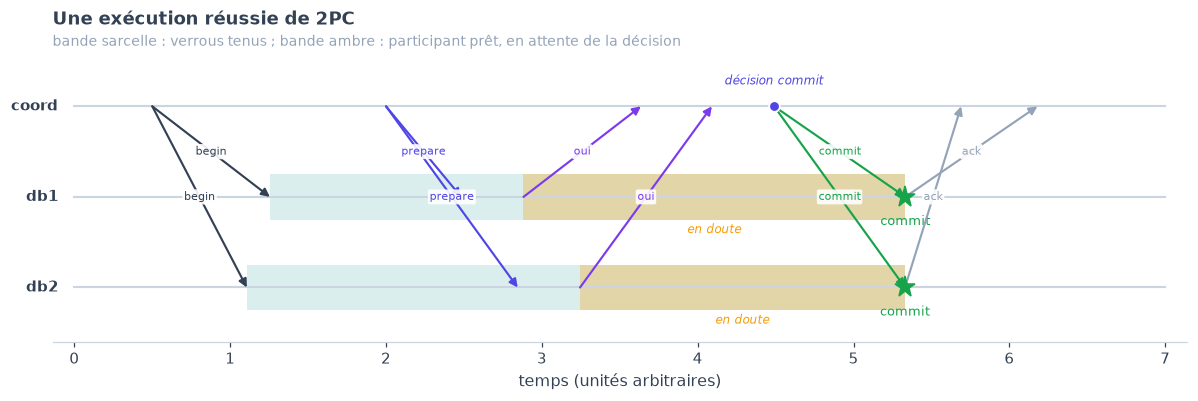

,participant,vote,issue,verrous_de,verrous_jusqu_à,durée_verrous,durée_en_doute
0,db1,yes,commit,1.25,5.33,4.08,2.45
1,db2,yes,commit,1.11,5.33,4.22,2.09


In [3]:
ok = run_2pc(t_max=7)
frise(ok, "Une exécution réussie de 2PC",
      "bande sarcelle : verrous tenus ; bande ambre : participant prêt, en attente de la décision").show()
ok.summary

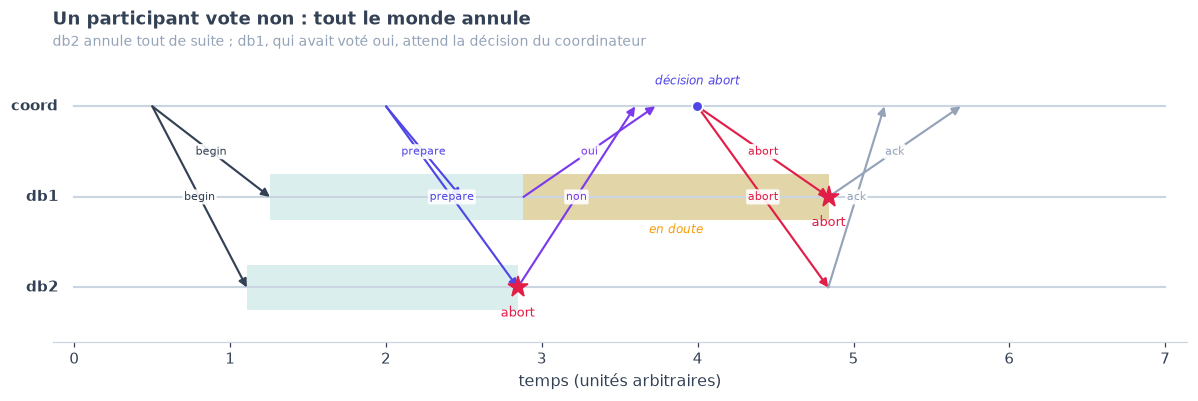

In [4]:
non = run_2pc(votes=["yes", "no"], t_max=7)
frise(non, "Un participant vote non : tout le monde annule",
      "db2 annule tout de suite ; db1, qui avait voté oui, attend la décision du coordinateur").show()

**Le coût.** Par rapport à une validation locale, 2PC ajoute deux allers-retours réseau
(préparation, décision) et des écritures durables (`fsync`) : chaque participant écrit
ses données et son vote avant de répondre oui, le coordinateur écrit sa décision avant de
la diffuser. Pour $n$ participants : $4n$ messages (dont $n$ accusés de réception
facultatifs pour la latence), $n + 1$ `fsync` sur le chemin critique, et des verrous
tenus pendant tout ce temps (bandes sarcelle). C'est une grande partie de la réputation
de lenteur des transactions distribuées.

> **À retenir.** 2PC sépare la validation en un vote (phase 1) et une décision (phase 2),
> prise par le coordinateur : commit seulement si tout le monde a voté oui.

## 3. Un système de promesses (section *A system of promises*)

Pourquoi 2PC est-il atomique alors que les messages peuvent se perdre aussi bien dans les
deux phases ? Parce qu'il contient **deux points de non-retour** :

1. quand un participant vote **oui**, il promet de pouvoir valider plus tard **quoi qu'il
   arrive** : il a écrit toutes les données sur disque et vérifié les contraintes ; il
   renonce à son droit d'annuler, sans pour autant valider ;
2. quand le coordinateur a reçu tous les votes, il **décide** et écrit sa décision dans
   son journal sur disque : c'est le **point de validation** (*commit point*). Ensuite, il
   renvoie la décision **indéfiniment** jusqu'à ce que chaque participant l'ait reçue ; un
   participant tombé en panne l'appliquera à son redémarrage.

Sur un seul nœud, ces deux événements sont confondus dans l'écriture du record de
validation. Le schéma résume les états du participant.

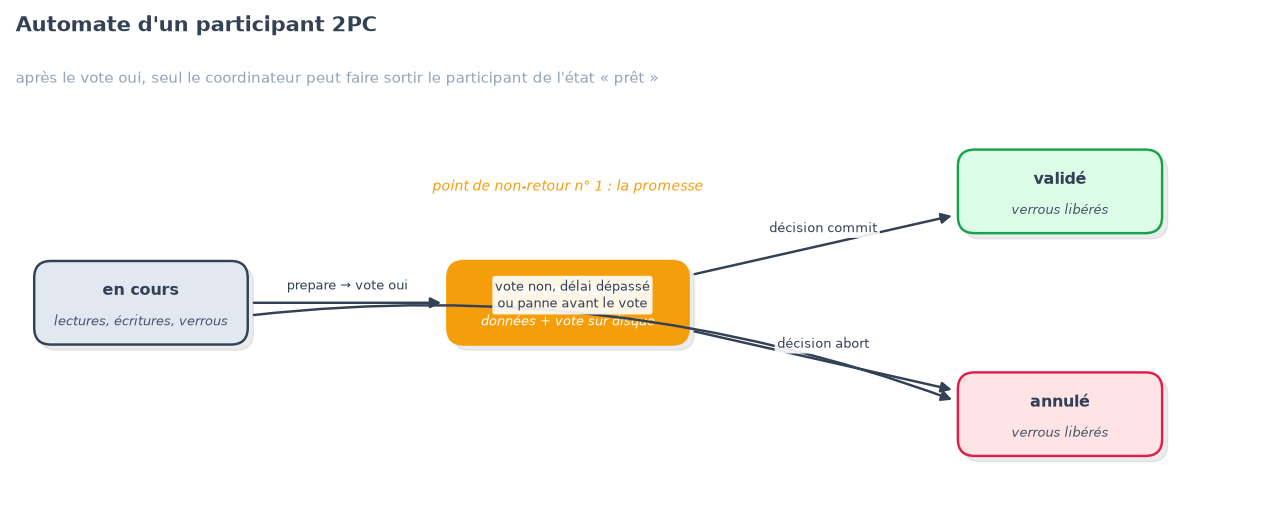

In [5]:
d = Diagram(13.5, 4.4, title="Automate d'un participant 2PC",
            subtitle="après le vote oui, seul le coordinateur peut faire sortir le participant de l'état « prêt »")
d.box("travail", 1.4, 2.2, "en cours", sub="lectures, écritures, verrous", color=SLATE, w=2.3)
d.box("pret", 6.0, 2.2, "prêt (en doute)", sub="données + vote sur disque", color=AMBER, w=2.6, filled=True)
d.box("commit", 11.3, 3.4, "validé", sub="verrous libérés", color=GREEN, w=2.2)
d.box("abort", 11.3, 1.0, "annulé", sub="verrous libérés", color=ROSE, w=2.2)
d.arrow("travail", "pret", "prepare → vote oui")
d.arrow("pret", "commit", "décision commit")
d.arrow("pret", "abort", "décision abort")
d.arrow("travail", "abort", "vote non, délai dépassé\nou panne avant le vote", rad=-0.12, label_pos=0.45)
d.note(6.0, 3.45, "point de non-retour n° 1 : la promesse", color=AMBER)
d.show()

**Vérification exhaustive.** Faisons tomber le coordinateur à **chaque instant** entre 0
et 8 (par pas de 0,05), avec redémarrage 10 unités plus tard, et regardons l'issue et la
durée pendant laquelle les participants restent en doute. Le coordinateur qui redémarre
relit son journal : s'il y trouve une décision, il la renvoie ; sinon, il annule
(**abandon présumé**).

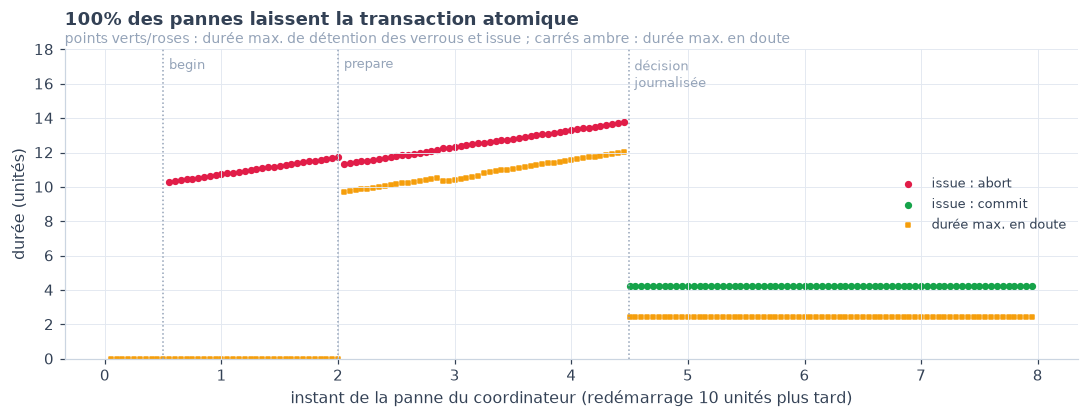

,min,max,count
issue,,,
abort,0.05,4.45,89
commit,4.50,7.95,70


In [6]:
instants = np.round(np.arange(0.05, 8.0, 0.05), 2)
lignes = []
for t in instants:
    r = run_2pc(crash={"coord": (t, t + 10)}, t_max=40)
    lignes.append(dict(t_panne=t, atomique=r.atomic, issue="/".join(sorted(set(r.summary["issue"]))),
                       doute_max=r.summary["durée_en_doute"].max(skipna=True),
                       verrous_max=r.summary["durée_verrous"].max()))
grille = pd.DataFrame(lignes).fillna({"doute_max": 0})
fig, ax = plt.subplots(figsize=(10, 3.9))
for issue, c in [("abort", ROSE), ("commit", GREEN)]:
    g_ = grille[grille["issue"] == issue]
    ax.scatter(g_["t_panne"], g_["verrous_max"], s=14, color=c, label=f"issue : {issue}")
ax.scatter(grille["t_panne"], grille["doute_max"], s=8, color=AMBER, marker="s", label="durée max. en doute")
for t, lab in [(0.5, "begin"), (2.0, "prepare"), (ok.coord.decided_at, "décision\njournalisée")]:
    ax.axvline(t, color=GRAY, ls=":", lw=1)
    ax.text(t + 0.05, 17.5, lab, fontsize=8.5, color=GRAY, va="top")
ax.set_xlabel("instant de la panne du coordinateur (redémarrage 10 unités plus tard)")
ax.set_ylabel("durée (unités)")
ax.set_ylim(0, 18)
ax.set_title(f"{grille['atomique'].mean():.0%} des pannes laissent la transaction atomique")
subtitle(ax, "points verts/roses : durée max. de détention des verrous et issue ; carrés ambre : durée max. en doute")
ax.legend(fontsize=8.5, loc="center right")
plt.tight_layout(); plt.show()
grille.groupby("issue")["t_panne"].agg(["min", "max", "count"])

Quel que soit l'instant de la panne, la transaction reste **atomique** (aucun mélange de
commit et d'abort) :

- panne **avant** l'écriture de la décision : au redémarrage, le journal ne contient pas
  de décision, le coordinateur annule ; les participants qui avaient voté oui restent en
  doute jusque-là (carrés ambre, de 10 à 12 unités) ; une panne avant `begin` n'a aucun
  effet visible (rien n'a commencé) ;
- panne **après** : la décision commit est dans le journal ; elle avait souvent déjà été
  reçue (pas de doute), sinon elle est renvoyée au redémarrage.

Le prix est visible sur l'axe vertical : pendant la panne, les verrous des participants
sont tenus jusqu'à 14 unités, contre environ 4 sans panne.

> **À retenir.** Deux promesses rendent 2PC atomique : le vote oui (je pourrai valider) et
> la décision journalisée (je la ferai appliquer, quoi qu'il arrive).

## 4. La panne du coordinateur : participants en doute (section *Coordinator failure*)

Si le coordinateur tombe **avant** d'envoyer `prepare`, un participant peut annuler sans
risque. Mais une fois qu'il a voté oui, il **ne peut plus décider seul** : il doit
attendre le coordinateur. Une transaction dans cet état est dite **en doute** (*in
doubt*). Reproduisons la situation du livre : le coordinateur décide commit et l'envoie,
mais le message vers db1 se perd (lien coupé) et le coordinateur tombe juste après.

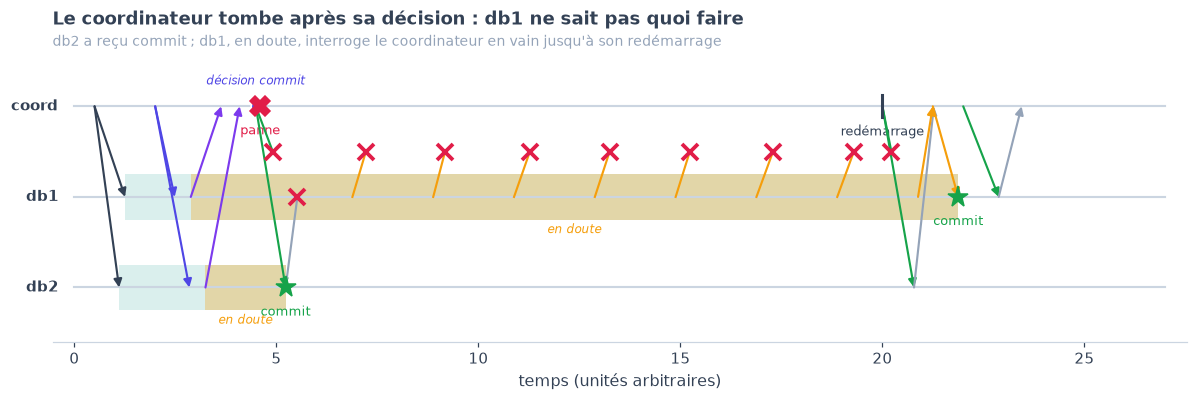

,participant,vote,issue,verrous_de,verrous_jusqu_à,durée_verrous,durée_en_doute
0,db1,yes,commit,1.25,21.88,20.62,18.99
1,db2,yes,commit,1.11,5.23,4.12,1.98


In [7]:
doute = run_2pc(crash={"coord": (4.6, 20)}, cuts={("coord", "db1"): (4.0, 20.5)}, t_max=27)
frise(doute, "Le coordinateur tombe après sa décision : db1 ne sait pas quoi faire",
      "db2 a reçu commit ; db1, en doute, interroge le coordinateur en vain jusqu'à son redémarrage",
      labels=False).show()
doute.summary

db2 a validé ; db1 a voté oui et ne sait pas si la transaction est validée. Un délai
d'attente ne l'aide pas : annuler la rendrait incohérente avec db2, valider serait aussi
dangereux (un autre participant aurait pu voter non). Les participants pourraient
s'informer entre eux, mais ce n'est pas prévu par 2PC. La seule issue : **attendre le redémarrage du coordinateur**, qui relit son
journal. C'est pourquoi la décision doit être sur disque **avant** d'être envoyée : le
point de validation de 2PC se ramène à une validation atomique locale sur le
coordinateur.

Si le coordinateur ne revient jamais (disque perdu), rien ne se débloque automatiquement :

In [8]:
perdu = run_2pc(crash={"coord": (2.9, None)}, t_max=30)
perdu.summary[["participant", "issue", "durée_verrous", "durée_en_doute"]]

,participant,issue,durée_verrous,durée_en_doute
0,db1,en doute,28.75,27.12
1,db2,en doute,28.89,26.76


Les deux participants restent en doute jusqu'à la fin de la simulation, verrous tenus :
seul un administrateur peut trancher. Pire, si seule la fin du journal du coordinateur est
perdue, il peut croire non validées des transactions validées et les annuler, ce qui
viole l'atomicité.

> **À retenir.** 2PC est un protocole **bloquant** : un participant qui a voté oui ne peut
> rien faire tant que le coordinateur n'est pas revenu.

## 5. Pourquoi ne pas décider seul ? (section *Three-phase commit*)

Ne pourrait-on pas rendre le protocole **non bloquant** ? Une tentation naturelle : le
participant en doute annule après un délai. Montrons que cela casse l'atomicité, dans le
scénario de la section 4.

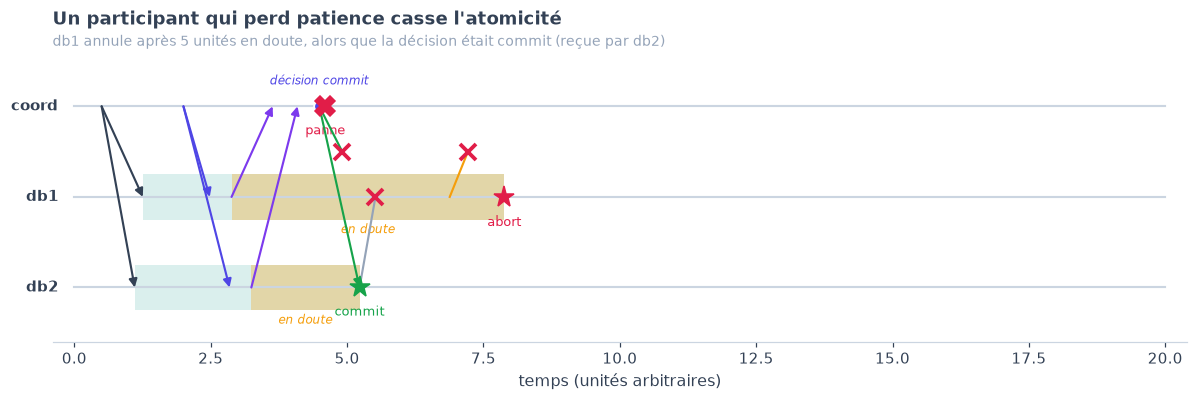

,participant,issue
0,db1,abort
1,db2,commit


In [9]:
class ParticipantImpatient(Participant2PC):
    """Participant qui annule unilatéralement s'il reste en doute plus de `patience`."""

    patience = 5.0

    def _prepared(self, src):
        super()._prepared(src)
        self.timer(self.patience, self._abandon_en_doute)

    def _abandon_en_doute(self):
        if self.state == "prepared" and self.outcome is None:
            self.record("abandon unilatéral (délai)")
            self._decide("abort")


net = tr.Network(seed=0, latency=(0.3, 0.9))
coord = net.add(tr.Coordinator2PC("coord", ["db1", "db2"]))
parts = [net.add(ParticipantImpatient("db1")), net.add(ParticipantImpatient("db2"))]
net.at(4.0, net.block, "coord", "db1")
net.at(4.6, net.crash, "coord")
net.run(until=20)
impatient = tr.TwoPCRun(net, coord, parts, pd.DataFrame(
    [dict(participant=p.name, issue=p.outcome or "en doute") for p in parts]), False, 20)
frise(impatient, "Un participant qui perd patience casse l'atomicité",
      "db1 annule après 5 unités en doute, alors que la décision était commit (reçue par db2)", labels=False).show()
impatient.summary

db2 a validé, db1 a annulé : exactement ce que 2PC devait empêcher. Le délai ne permet
pas de distinguer un coordinateur **lent** d'un coordinateur **en panne**, ni de savoir
ce qu'il avait décidé.

La **validation à trois phases** (3PC) a été proposée comme alternative non bloquante,
mais elle suppose un réseau à délais **bornés** et des nœuds à temps de réponse bornés.
Dans les systèmes réels (délais réseau et pauses de processus non bornés, chapitre
8), elle ne garantit pas l'atomicité. La solution pratique est de remplacer le
coordinateur unique par un protocole de **consensus** tolérant aux pannes (chapitre
9).

> **À retenir.** Un participant en doute ne peut pas décider seul : un délai confond
> lenteur et panne. Se débarrasser du blocage exige un consensus, pas un minuteur.

## 6. Transactions distribuées hétérogènes et XA (sections *Distributed Transactions in Practice*, *Exactly-once message processing*, *XA transactions*)

Les transactions distribuées ont une réputation mitigée : garantie précieuse pour les
uns, source de problèmes opérationnels et de lenteur pour les autres (beaucoup de
services cloud refusent de les offrir). Une partie du coût vient des `fsync`
supplémentaires et des allers-retours. Le livre distingue deux types souvent confondus :

- les transactions **internes** à une base distribuée (tous les participants exécutent le
  même logiciel) : libres d'utiliser des protocoles et optimisations propres, elles
  fonctionnent souvent bien ;
- les transactions **hétérogènes**, entre technologies différentes (deux bases de
  fournisseurs différents, une base et un courtier de messages) : bien plus délicates.

**Exemple : « exactement une fois ».** Un message n'est acquitté auprès du courtier que si
la transaction qui le traite a été validée dans la base, les deux dans une seule
transaction atomique. En cas d'échec, tout est annulé et le courtier relivre le message :
l'effet du message s'applique **exactement une fois**, même après plusieurs tentatives. À
condition que **tous** les effets participent au protocole : un courriel envoyé par un
serveur qui ne parle pas 2PC peut partir deux fois.

**XA** (*eXtended Architecture*, X/Open, 1991) est le standard de 2PC entre technologies
hétérogènes, pris en charge par PostgreSQL, MySQL, Db2, SQL Server, Oracle, et des
courtiers comme ActiveMQ, HornetQ, MSMQ ou IBM MQ. Ce n'est pas un protocole réseau mais
une **API C** (en Java : JTA, avec les pilotes JDBC et JMS) entre l'application et le
coordinateur.

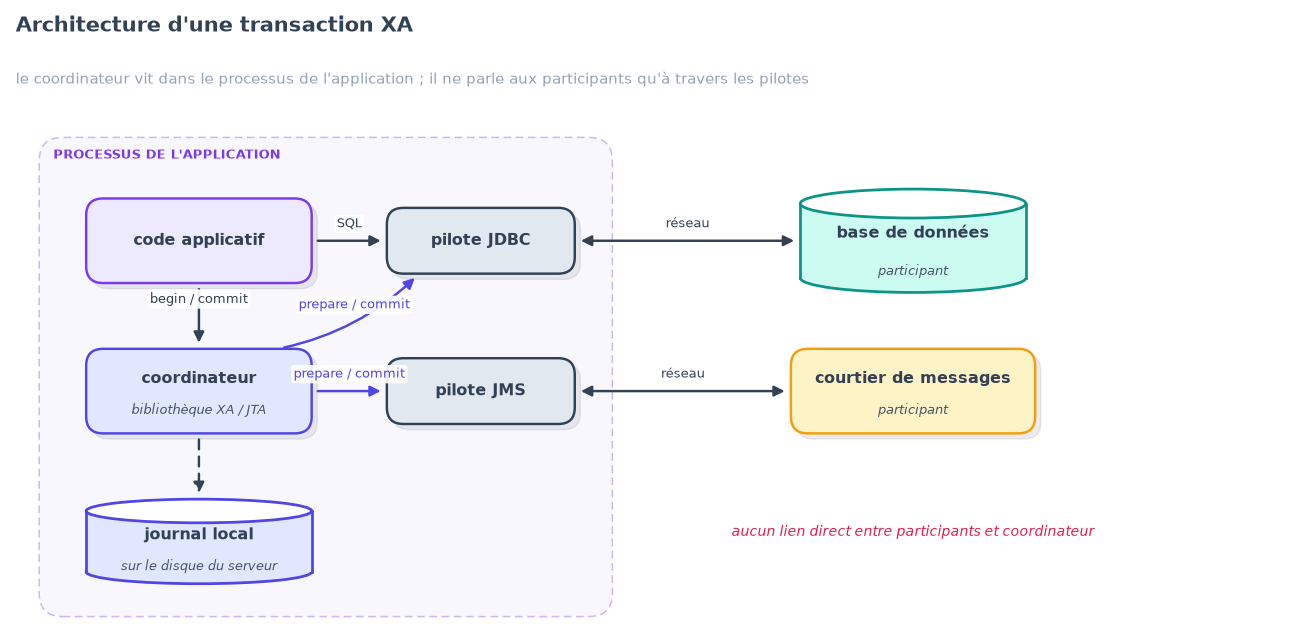

In [10]:
d = Diagram(13.5, 5.6, title="Architecture d'une transaction XA",
            subtitle="le coordinateur vit dans le processus de l'application ; il ne parle aux participants qu'à travers les pilotes")
d.group(0.3, 0.1, 6.4, 5.2, "processus de l'application", color=VIOLET)
d.box("app", 2.0, 4.1, "code applicatif", color=VIOLET, w=2.4)
d.box("coord", 2.0, 2.5, "coordinateur", sub="bibliothèque XA / JTA", color=INDIGO, w=2.4)
d.box("log", 2.0, 0.9, "journal local", sub="sur le disque du serveur", color=INDIGO, kind="db", w=2.4, h=0.9)
d.box("drv1", 5.0, 4.1, "pilote JDBC", color=SLATE, w=2.0, h=0.7)
d.box("drv2", 5.0, 2.5, "pilote JMS", color=SLATE, w=2.0, h=0.7)
d.box("db", 9.6, 4.1, "base de données", sub="participant", color=TEAL, kind="db", w=2.4, h=1.1)
d.box("mq", 9.6, 2.5, "courtier de messages", sub="participant", color=AMBER, w=2.6)
d.arrow("app", "coord", "begin / commit")
d.arrow("coord", "log", style="dashed")
d.arrow("app", "drv1", "SQL")
d.arrow("coord", "drv1", "prepare / commit", rad=0.15, color=INDIGO)
d.arrow("coord", "drv2", "prepare / commit", color=INDIGO)
d.arrow("drv1", "db", "réseau", both=True)
d.arrow("drv2", "mq", "réseau", both=True)
d.note(9.6, 1.0, "aucun lien direct entre participants et coordinateur", color=ROSE)
d.show()

Le coordinateur suit les participants, collecte leurs votes via les pilotes, et note ses
décisions dans un journal sur le **disque local** du serveur d'applications. Si le
processus ou la machine tombe, le coordinateur tombe avec : il faut redémarrer ce serveur
précis pour que la bibliothèque relise son journal et termine les transactions en doute.
La base ne peut pas contacter le coordinateur elle-même : tout passe par le pilote.

> **À retenir.** XA = 2PC entre systèmes hétérogènes, via une API ; le coordinateur est
> une bibliothèque dans l'application, avec un journal sur son disque local.

## 7. Verrous tenus en doute et reprise après panne (sections *Holding locks while in doubt* et *Recovering from coordinator failure*)

Pourquoi s'inquiéter d'une transaction en doute ? À cause des **verrous**. Une
transaction tient des verrous exclusifs sur les lignes qu'elle a écrites (pas d'écriture
sale), et en 2PL des verrous partagés sur ce qu'elle a lu. Elle ne peut pas les rendre
avant la décision. Si le coordinateur met 20 minutes à redémarrer, les verrous sont tenus
20 minutes ; si son journal est perdu, pour toujours (jusqu'à l'intervention d'un
administrateur). Toute transaction qui veut ces lignes est bloquée : une grande partie de
l'application peut devenir indisponible.

Mesurons la durée de détention des verrous en fonction du temps de redémarrage du
coordinateur (panne juste après le début de la phase de préparation), et le nombre de
transactions bloquées si 50 transactions par unité de temps veulent les mêmes lignes.

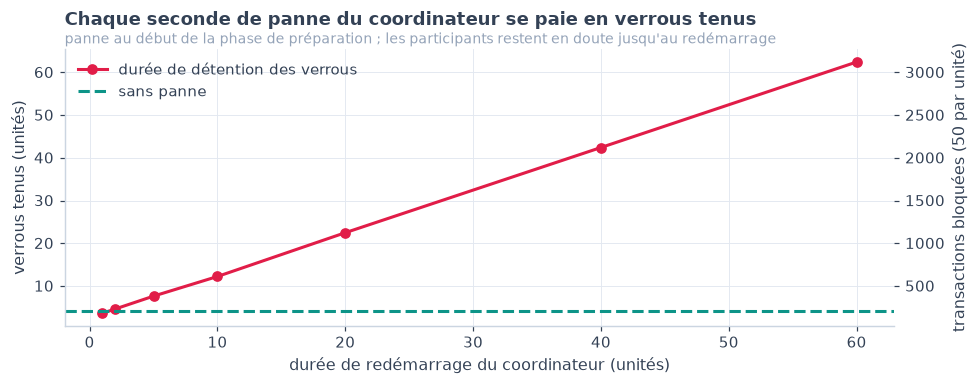

In [11]:
reboot = np.array([1, 2, 5, 10, 20, 40, 60])
duree = [run_2pc(crash={"coord": (2.9, 2.9 + r_)}, t_max=200).summary["durée_verrous"].max() for r_ in reboot]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(reboot, duree, marker="o", color=ROSE, label="durée de détention des verrous")
ax.axhline(ok.summary["durée_verrous"].max(), color=TEAL, ls="--", label="sans panne")
ax2 = ax.twinx()
ax2.plot(reboot, np.array(duree) * 50, alpha=0)
ax2.set_ylabel("transactions bloquées (50 par unité)", color=SLATE)
ax2.grid(False)
ax.set_xlabel("durée de redémarrage du coordinateur (unités)")
ax.set_ylabel("verrous tenus (unités)")
ax.set_title("Chaque seconde de panne du coordinateur se paie en verrous tenus")
subtitle(ax, "panne au début de la phase de préparation ; les participants restent en doute jusqu'au redémarrage")
ax.legend()
plt.tight_layout(); plt.show()

La durée de détention suit exactement le temps de redémarrage (plus le temps du
protocole) : la disponibilité des lignes concernées dépend de celle d'un processus
applicatif.

**Transactions orphelines.** En théorie, le coordinateur relit son journal et tout
rentre dans l'ordre. En pratique, des transactions en doute **orphelines** existent (journal
perdu ou corrompu par un bogue). Elles restent dans la base, verrous tenus, même après un
redémarrage de la base (une implémentation correcte de 2PC **doit** conserver les verrous
d'une transaction préparée à travers les redémarrages, sinon l'atomicité serait en jeu ;
le lab PostgreSQL de ce chapitre le vérifie). Seul un administrateur peut décider, en
examinant chaque participant, souvent sous pression pendant une panne grave. Les
implémentations XA offrent une échappatoire, les **décisions heuristiques** : un
participant tranche seul ; « heuristique » est ici un euphémisme pour « atomicité
probablement violée » (section 5).

> **À retenir.** Une transaction en doute garde ses verrous jusqu'à la décision, même à
> travers les redémarrages : la panne d'un coordinateur se propage en indisponibilité.

## 8. Les limites des transactions XA (section *Limitations of distributed transactions*)

| problème | conséquence |
|---|---|
| coordinateur sur un seul nœud | point de défaillance unique de tout le système |
| journal du coordinateur sur le disque du serveur d'applications | ce serveur n'est plus sans état : son disque devient aussi précieux que les bases |
| pas de communication directe coordinateur-participants | même avec un coordinateur répliqué, le code applicatif reste un point de défaillance |
| plus petit dénominateur commun | pas de détection d'interblocages entre systèmes, pas de SSI entre systèmes |
| sensibilité aux pannes | une panne d'un participant fait échouer toute la transaction (amplification des pannes) |

Garder des systèmes hétérogènes cohérents entre eux reste un vrai problème, mais il faut
d'autres solutions (chapitre 11).

> **À retenir.** XA rend l'atomicité possible entre technologies, mais en fait dépendre la
> disponibilité de tout le système d'un coordinateur fragile et d'un protocole au plus
> petit dénominateur commun.